# Titanic: exploring the data and making a first submission

Competition page: https://www.kaggle.com/competitions/titanic

You need three files from the Data tab: `train.csv`, `test.csv` and `gender_submission.csv`.

## 0. Upload the files to Colab

Run the next cell and pick the three files. Alternatively, drag them into the Files panel on the left (folder icon) and skip the cell.
Uploaded files are deleted when the runtime restarts, so after a restart you have to upload them again.

In [1]:
from google.colab import files
uploaded = files.upload()

Saving gender_submission.csv to gender_submission.csv
Saving test.csv to test.csv
Saving train.csv to train.csv


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

train = pd.read_csv('train.csv')
test = pd.read_csv('test.csv')
sample = pd.read_csv('gender_submission.csv')

print(train.shape, test.shape, sample.shape)

(891, 12) (418, 11) (418, 2)


In [3]:
train.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


## 1. What is in the data

Each row of `train.csv` is one passenger. `test.csv` has the same columns except `Survived`, which is what we have to predict.
`gender_submission.csv` shows the format Kaggle expects: one row per test passenger with `PassengerId` and a 0/1 prediction
(this particular file predicts that all women survived and all men died).

| Column | Meaning | Type |
|---|---|---|
| `PassengerId` | Row number, carries no information | identifier |
| `Survived` | 1 = survived, 0 = died | target |
| `Pclass` | Ticket class: 1 = upper, 2 = middle, 3 = lower. Often used as a proxy for socio-economic status | ordinal |
| `Name` | Full name, includes a title (Mr, Mrs, Miss, Master, ...) | text |
| `Sex` | male or female | categorical |
| `Age` | Age in years. Fractional below 1; estimated ages end in .5 | numeric |
| `SibSp` | Number of siblings and spouses on board | count |
| `Parch` | Number of parents and children on board | count |
| `Ticket` | Ticket number. Several passengers can share one ticket | text |
| `Fare` | Price of the ticket (of the whole ticket, see section 4) | numeric |
| `Cabin` | Cabin number, mostly missing | text |
| `Embarked` | Port: C = Cherbourg, Q = Queenstown, S = Southampton | categorical |

The type of a column matters twice later on: it decides which plot to use (histogram for numbers, bar chart for categories)
and how to turn the column into numbers for a model.

In [4]:
for col in train.columns:
    print(col, train[col].dtype, train[col].nunique(), 'distinct values')

PassengerId int64 891 distinct values
Survived int64 2 distinct values
Pclass int64 3 distinct values
Name object 891 distinct values
Sex object 2 distinct values
Age float64 88 distinct values
SibSp int64 7 distinct values
Parch int64 7 distinct values
Ticket object 681 distinct values
Fare float64 248 distinct values
Cabin object 147 distinct values
Embarked object 3 distinct values


`Pclass`, `SibSp` and `Parch` are stored as numbers but take only a handful of values, so they behave more like categories.
We will plot them with bar charts rather than histograms.

## 2. Summary statistics

In [5]:
train.describe()

,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
count,891.000000,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,446.000000,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,257.353842,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,1.000000,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,223.500000,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,446.000000,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,668.500000,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,891.000000,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


What to notice:

- `Survived` has a mean of 0.38, so 38% of passengers in train survived. A "model" that always predicts "died"
  is already right 62% of the time, and any real model has to beat that.
- `Age` has a count of 714 instead of 891: 177 ages are missing. Ages range from 0.42 (a baby of five months) to 80.
- `Fare`: the mean (32.2) is more than twice the median (14.5) and the maximum is 512. A few very expensive tickets pull
  the mean up, which is the sign of a long right tail. 15 passengers have a fare of 0.
- `SibSp` and `Parch` have a median of 0: most people travelled without relatives.

In [6]:
train[['Sex', 'Embarked', 'Ticket', 'Cabin']].describe()

,Sex,Embarked,Ticket,Cabin
count,891,889,891,204
unique,2,3,681,147
top,male,S,347082,G6
freq,577,644,7,4


For text columns `describe` shows how many values are filled, how many are distinct and which one is the most frequent.
891 passengers share 681 ticket numbers, so some tickets were bought for a group. `Cabin` is filled for only 204 passengers.

## 3. Missing values

In [7]:
print('train')
for col in train.columns:
    n = train[col].isna().sum()
    if n > 0:
        print(' ', col, n, 'missing,', round(100 * n / len(train), 1), '%')

print('test')
for col in test.columns:
    n = test[col].isna().sum()
    if n > 0:
        print(' ', col, n, 'missing,', round(100 * n / len(test), 1), '%')

train
  Age 177 missing, 19.9 %
  Cabin 687 missing, 77.1 %
  Embarked 2 missing, 0.2 %
test
  Age 86 missing, 20.6 %
  Fare 1 missing, 0.2 %
  Cabin 327 missing, 78.2 %


Three columns have gaps in train: `Cabin` (77%), `Age` (20%) and `Embarked` (2 rows). In test, `Age`, `Cabin` and one `Fare`
are missing. We decide what to do with them in section 6, after looking at the data.

## 4. Distributions of single features

### Age and Fare

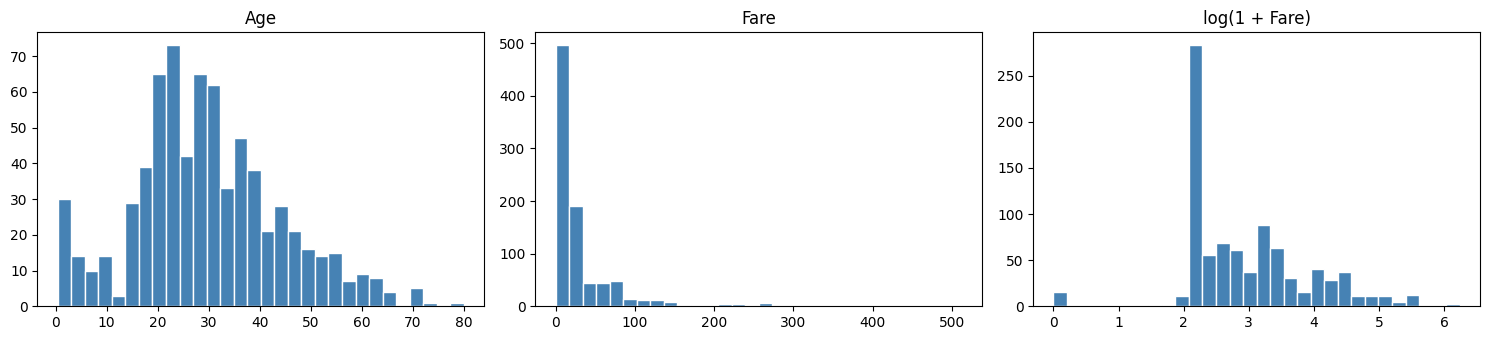

skewness of Age: 0.39
skewness of Fare: 4.79
skewness of log(1 + Fare): 0.39


In [8]:
fig, axes = plt.subplots(1, 3, figsize=(15, 3.5))
axes[0].hist(train['Age'].dropna(), bins=30, color='steelblue', edgecolor='white')
axes[0].set_title('Age')
axes[1].hist(train['Fare'], bins=30, color='steelblue', edgecolor='white')
axes[1].set_title('Fare')
axes[2].hist(np.log1p(train['Fare']), bins=30, color='steelblue', edgecolor='white')
axes[2].set_title('log(1 + Fare)')
plt.tight_layout()
plt.show()

print('skewness of Age:', round(train['Age'].skew(), 2))
print('skewness of Fare:', round(train['Fare'].skew(), 2))
print('skewness of log(1 + Fare):', round(np.log1p(train['Fare']).skew(), 2))

### Fare is per ticket, not per person

In [9]:
passengers_per_ticket = train.groupby('Ticket')['PassengerId'].count()
print('tickets shared by more than one passenger:', (passengers_per_ticket > 1).sum())

train[train['Ticket'] == 'CA. 2343'][['Name', 'Pclass', 'Fare', 'SibSp', 'Parch']]

tickets shared by more than one passenger: 134


,Name,Pclass,Fare,SibSp,Parch
159,"Sage, Master. Thomas Henry",3,69.55,8,2
180,"Sage, Miss. Constance Gladys",3,69.55,8,2
201,"Sage, Mr. Frederick",3,69.55,8,2
324,"Sage, Mr. George John Jr",3,69.55,8,2
792,"Sage, Miss. Stella Anna",3,69.55,8,2
846,"Sage, Mr. Douglas Bullen",3,69.55,8,2
863,"Sage, Miss. Dorothy Edith ""Dolly""",3,69.55,8,2


Passengers on the same ticket have the same fare. The Sage family travelled third class, yet their fare of 69.55 is above
the median first class fare (60.3), because it is the price for the whole family of 11 (seven of them are in train).
Dividing `Fare` by the number of people on the ticket would give something closer to the price per person.

### Categories and counts

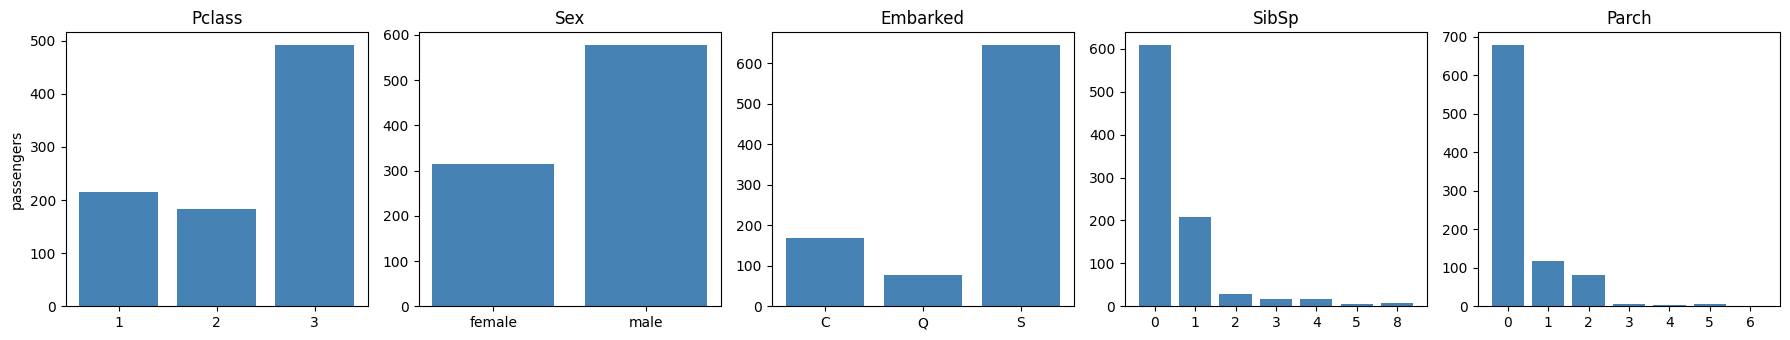

In [10]:
cat_cols = ['Pclass', 'Sex', 'Embarked', 'SibSp', 'Parch']

fig, axes = plt.subplots(1, 5, figsize=(18, 3.5))
for i in range(len(cat_cols)):
    col = cat_cols[i]
    counts = train[col].value_counts().sort_index()
    axes[i].bar(counts.index.astype(str), counts.values, color='steelblue')
    axes[i].set_title(col)
axes[0].set_ylabel('passengers')
plt.tight_layout()
plt.show()

55% of passengers travelled third class, 65% are men and 72% boarded in Southampton.
68% had no siblings or spouse on board and 76% had no parents or children.

## 5. Features and survival

For a 0/1 column the mean is the share of ones, so `train.groupby(col)['Survived'].mean()` is the survival rate in each group.
The dashed line in the plots is the overall rate (38%).

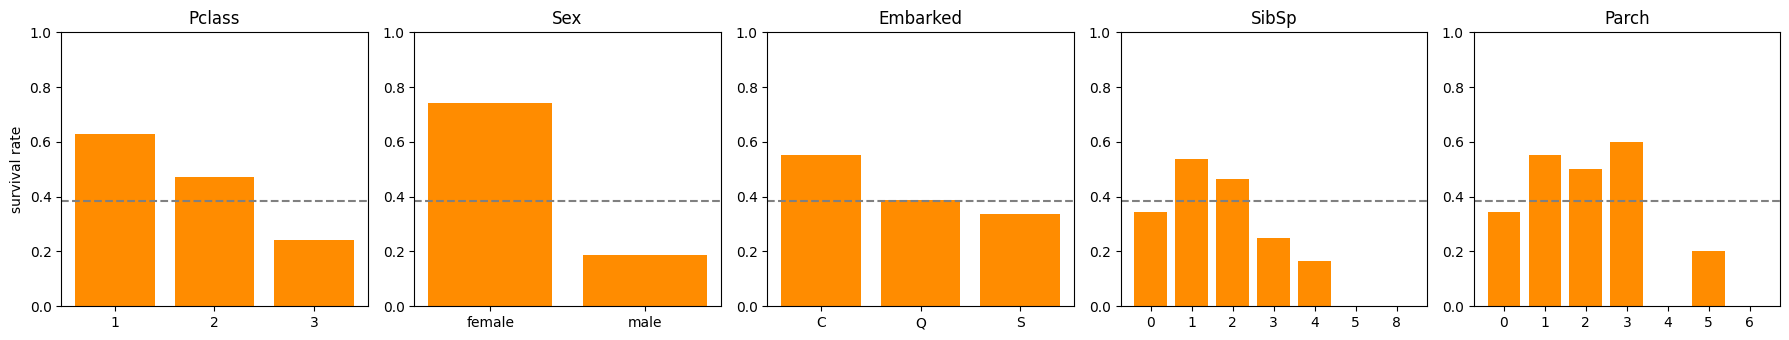

In [11]:
overall = train['Survived'].mean()

fig, axes = plt.subplots(1, 5, figsize=(18, 3.5))
for i in range(len(cat_cols)):
    col = cat_cols[i]
    rate = train.groupby(col)['Survived'].mean()
    axes[i].bar(rate.index.astype(str), rate.values, color='darkorange')
    axes[i].axhline(overall, color='gray', linestyle='--')
    axes[i].set_ylim(0, 1)
    axes[i].set_title(col)
axes[0].set_ylabel('survival rate')
plt.tight_layout()
plt.show()

In [12]:
# group sizes matter: a rate computed on 5 people is not reliable
for col in ['SibSp', 'Parch']:
    print(train.groupby(col)['Survived'].agg(['mean', 'count']).round(2))
    print()

       mean  count
SibSp             
0      0.35    608
1      0.54    209
2      0.46     28
3      0.25     16
4      0.17     18
5      0.00      5
8      0.00      7

       mean  count
Parch             
0      0.34    678
1      0.55    118
2      0.50     80
3      0.60      5
4      0.00      4
5      0.20      5
6      0.00      1



- Sex is the strongest signal: 74% of women survived against 19% of men.
- Class: 63% survived in first class, 47% in second, 24% in third.
- Port: 55% of those who boarded in Cherbourg survived, against 34% from Southampton. This does not mean the port itself mattered,
  see the next cell.
- Relatives: passengers with one sibling or spouse on board survived more often (54%) than those with none (35%).
  Large families did badly, but groups with 3 or more siblings/spouses have fewer than 20 people each, so their rates are noisy.

In [13]:
# share of each class among the passengers from each port
pd.crosstab(train['Embarked'], train['Pclass'], normalize='index').round(2)

Pclass,1,2,3
Embarked,,,
C,0.51,0.10,0.39
Q,0.03,0.04,0.94
S,0.20,0.25,0.55


Half of the Cherbourg passengers (51%) travelled first class, compared with 20% of the Southampton passengers.
So Cherbourg looks "lucky" mostly because it had many first class passengers.
This is called confounding: a feature can be related to the target only through another feature.

In [14]:
train.pivot_table(index='Sex', columns='Pclass', values='Survived', aggfunc='mean').round(2)

Pclass,1,2,3
Sex,,,
female,0.97,0.92,0.50
male,0.37,0.16,0.14


### Age and survival

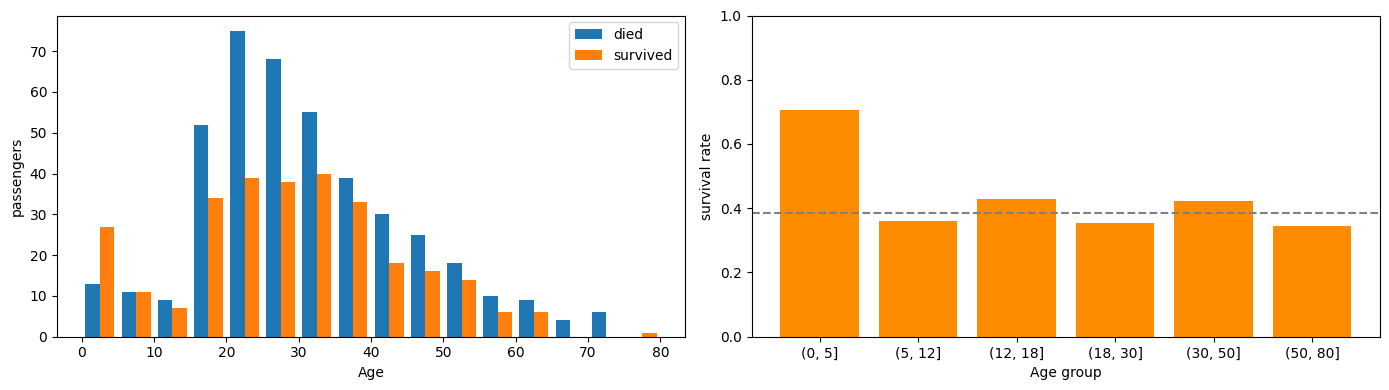

In [15]:
died = train[train['Survived'] == 0]['Age'].dropna()
survived = train[train['Survived'] == 1]['Age'].dropna()

age_groups = pd.cut(train['Age'], bins=[0, 5, 12, 18, 30, 50, 80])
rate_by_age = train.groupby(age_groups, observed=True)['Survived'].mean()

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
axes[0].hist([died, survived], bins=range(0, 85, 5), label=['died', 'survived'])
axes[0].set_xlabel('Age')
axes[0].set_ylabel('passengers')
axes[0].legend()
axes[1].bar(rate_by_age.index.astype(str), rate_by_age.values, color='darkorange')
axes[1].axhline(overall, color='gray', linestyle='--')
axes[1].set_ylim(0, 1)
axes[1].set_xlabel('Age group')
axes[1].set_ylabel('survival rate')
plt.tight_layout()
plt.show()

Children under 5 are the only group where more passengers survived than died (71% survival).
Above that age the rate stays between 34% and 43%.

In [16]:
train[['Survived', 'Pclass', 'Age', 'SibSp', 'Parch', 'Fare']].corr()['Survived'].round(3)

,Survived
Survived,1.000
Pclass,-0.338
Age,-0.077
SibSp,-0.035
Parch,0.082
Fare,0.257


Correlation measures how well a straight line describes the relation. `Age` has a correlation of only −0.08 with survival,
even though small children clearly survived more often: the effect sits in one corner of the age range, and a straight line
through all ages averages it away. A low correlation does not mean a feature is useless.
`Sex` is not in this list because it is still text; we convert it in section 7.

## 6. Dealing with missing values

- `Cabin`: 77% missing, too little to fill in, so we drop the column. Whether the cabin is known is still informative
  (67% survival when it is known, 30% when it is not), mostly because cabins were recorded for first class passengers.
  A 0/1 flag "cabin known" could be a feature; we leave it out to keep things simple.
- `Embarked`: only 2 rows in train, we remove them.
- `Age`: 20% missing, too much to throw away, so we fill it with a median. But the median age differs a lot between groups
  (see the next cell), so we use the median of the passenger's sex and class rather than one number for everybody.
- `Fare`: one value missing in test, filled with the median fare of that passenger's class.
- In test we cannot drop rows at all: Kaggle needs a prediction for each of the 418 passengers.

In [17]:
age_medians = train.groupby(['Sex', 'Pclass'])['Age'].median()
print(age_medians)

Sex     Pclass
female  1         35.0
        2         28.0
        3         21.5
male    1         40.0
        2         30.0
        3         25.0
Name: Age, dtype: float64


In [18]:
def fill_age(df):
    df = df.copy()
    for sex in ['female', 'male']:
        for pclass in [1, 2, 3]:
            rows = (df['Sex'] == sex) & (df['Pclass'] == pclass) & df['Age'].isna()
            df.loc[rows, 'Age'] = age_medians[(sex, pclass)]
    return df


age_before = train['Age'].copy()

train = train.drop(columns=['Cabin'])
test = test.drop(columns=['Cabin'])

# two rows without a port
train = train[train['Embarked'].notna()]

train = fill_age(train)
test = fill_age(test)

fare_by_class = train.groupby('Pclass')['Fare'].median()
for pclass in [1, 2, 3]:
    rows = (test['Pclass'] == pclass) & test['Fare'].isna()
    test.loc[rows, 'Fare'] = fare_by_class[pclass]

print(train.shape, test.shape)
print('missing values left:', train.isna().sum().sum(), test.isna().sum().sum())

(889, 11) (418, 10)
missing values left: 0 0


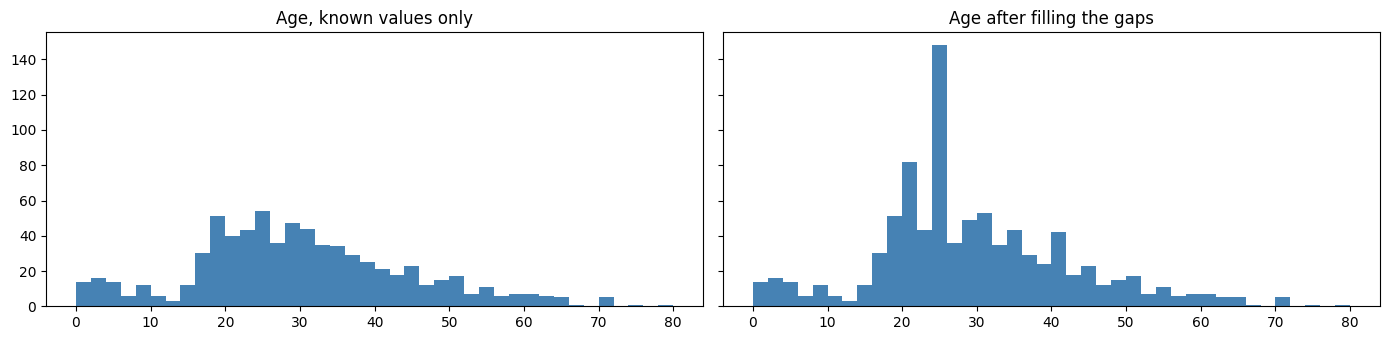

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(14, 3.5), sharey=True)
axes[0].hist(age_before.dropna(), bins=range(0, 82, 2), color='steelblue')
axes[0].set_title('Age, known values only')
axes[1].hist(train['Age'], bins=range(0, 82, 2), color='steelblue')
axes[1].set_title('Age after filling the gaps')
plt.tight_layout()
plt.show()

The filled values show up as spikes at the group medians. With a single overall median (28) all 177 of them would land in one bar.
Either way they are guesses, and the model cannot tell them from real ages. A common fix is an extra 0/1 column "age was missing".

## 7. Turning features into numbers

Models need numbers. `Sex` becomes 1 for female and 0 for male. `Embarked` becomes three 0/1 columns, one per port,
rather than codes 0, 1, 2: codes would suggest an order (Q between C and S) that does not exist.
`Pclass` stays as 1, 2, 3 because it does have an order. `Name`, `Ticket` and `PassengerId` are left out.

In [20]:
def prepare(df):
    X = df[['Pclass', 'Sex', 'Age', 'SibSp', 'Parch', 'Fare', 'Embarked']].copy()
    X['Sex'] = (X['Sex'] == 'female').astype(int)
    X = pd.get_dummies(X, columns=['Embarked'], dtype=int)
    return X


X = prepare(train)
y = train['Survived']
X_test = prepare(test)

print(X.columns.tolist())
X.head()

['Pclass', 'Sex', 'Age', 'SibSp', 'Parch', 'Fare', 'Embarked_C', 'Embarked_Q', 'Embarked_S']


,Pclass,Sex,Age,SibSp,Parch,Fare,Embarked_C,Embarked_Q,Embarked_S
0,3,0,22.0,1,0,7.2500,0,0,1
1,1,1,38.0,1,0,71.2833,1,0,0
2,3,1,26.0,0,0,7.9250,0,0,1
3,1,1,35.0,1,0,53.1000,0,0,1
4,3,0,35.0,0,0,8.0500,0,0,1


## 8. Models

We do not have the answers for test, so we keep 20% of train aside and compare models on it before submitting anything.
`stratify=y` keeps the share of survivors (38%) the same in both parts.

In [21]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.metrics import accuracy_score

X_tr, X_val, y_tr, y_val = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
print(X_tr.shape, X_val.shape)

# two simple rules to compare with
print('everyone died:', round(accuracy_score(y_val, np.zeros(len(y_val))), 3))
print('all women survived:', round(accuracy_score(y_val, X_val['Sex']), 3))

(711, 9) (178, 9)
everyone died: 0.618
all women survived: 0.77


In [22]:
logreg = LogisticRegression(max_iter=1000)
logreg.fit(X_tr, y_tr)

pred = logreg.predict(X_val)
print('logistic regression:', round(accuracy_score(y_val, pred), 3))

logistic regression: 0.82


In [23]:
# positive coefficient: raises the chance of survival, negative: lowers it
coefs = pd.Series(logreg.coef_[0], index=X.columns)
print(coefs.sort_values().round(2))

Pclass       -1.10
Embarked_S   -0.28
SibSp        -0.26
Parch        -0.08
Age          -0.04
Fare          0.00
Embarked_C    0.01
Embarked_Q    0.26
Sex           2.52
dtype: float64


A coefficient is the change in log-odds of survival per one unit of the feature. For `Sex` one unit is the difference between
a man and a woman, so its coefficient is large. For `Age` one unit is one year: about −0.04 per year looks small,
but over 30 years it adds up to about −1.2, comparable to moving one class down.

In [24]:
gb = GradientBoostingClassifier(n_estimators=200, max_depth=3, learning_rate=0.05, random_state=42)
gb.fit(X_tr, y_tr)

pred = gb.predict(X_val)
print('gradient boosting:', round(accuracy_score(y_val, pred), 3))

gradient boosting: 0.82


In [25]:
importance = pd.Series(gb.feature_importances_, index=X.columns)
print(importance.sort_values(ascending=False).round(3))

Sex           0.469
Fare          0.175
Pclass        0.131
Age           0.130
SibSp         0.063
Embarked_S    0.012
Embarked_Q    0.012
Parch         0.004
Embarked_C    0.003
dtype: float64


Feature importance shows how much each feature helped the trees' splits. Sex comes first, followed by fare, class and age,
which matches what we saw in section 5. Importance does not show the direction (whether a feature raises or lowers the chance
of survival); for that, look at the plots or at the logistic regression coefficients.

A caveat about the comparison: the validation part has 178 passengers, so one wrong answer moves accuracy by 0.6 points.
Differences of one or two points between models are within that noise. On this split the two models score about the same,
yet they disagree on dozens of test passengers (section 9), so their Leaderboard scores can still differ.

## 9. Submissions

Now we refit both models on the whole train and predict test. The submission file is built from `gender_submission.csv`:
we take it as it is and replace only the `Survived` column. For that the passengers in the sample must be in the same order
as in test, which we check first.

In [26]:
print((sample['PassengerId'] == test['PassengerId']).all())

True


In [27]:
logreg.fit(X, y)
gb.fit(X, y)

sub_logreg = sample.copy()
sub_logreg['Survived'] = logreg.predict(X_test)
sub_logreg.to_csv('submission_logreg.csv', index=False)

sub_gb = sample.copy()
sub_gb['Survived'] = gb.predict(X_test)
sub_gb.to_csv('submission_gb.csv', index=False)

print(sub_logreg.shape, sub_gb.shape)
print('the two models disagree on', (sub_logreg['Survived'] != sub_gb['Survived']).sum(), 'passengers')
sub_gb.head()

(418, 2) (418, 2)
the two models disagree on 47 passengers


,PassengerId,Survived
0,892,0
1,893,0
2,894,0
3,895,0
4,896,0


In [28]:
files.download('submission_logreg.csv')
files.download('submission_gb.csv')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>